## Imports

In [90]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from torchvision.datasets import CelebA
from transformers import CLIPModel, CLIPProcessor

In [91]:
torch.cuda.is_available()

True

## Embedding CelebA images using CLIP

### Experiments

In [7]:
data_root = Path("../data")
Path.exists(data_root)

True

In [8]:
celeba = CelebA(root=data_root, split="test", download=False)
len(celeba)

19962

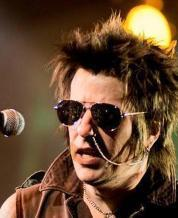

In [28]:
celeba[10][0]

Load CLIP from huggingface

In [2]:
CLIP_VERSION = "openai/clip-vit-base-patch32"

model = CLIPModel.from_pretrained(CLIP_VERSION)
model = model.to("cuda")
model.eval()

processor = CLIPProcessor.from_pretrained(CLIP_VERSION)

Loading weights: 100%|██████████| 398/398 [00:00<00:00, 8362.22it/s]


Lets try to embed a few images using it

In [9]:
imgs = [celeba[idx][0] for idx in range(2)]
imgs

[<PIL.JpegImagePlugin.JpegImageFile image mode=RGB size=178x218>,
 <PIL.JpegImagePlugin.JpegImageFile image mode=RGB size=178x218>]

In [10]:
inputs = processor(images=imgs, return_tensors="pt", device="cuda")

inputs["pixel_values"].shape

torch.Size([2, 3, 224, 224])

In [11]:
with torch.inference_mode():
    img_embeds = model.get_image_features(inputs["pixel_values"])

img_embeds.pooler_output.shape

torch.Size([2, 512])

In [12]:
img_embeds.pooler_output

tensor([[ 0.4089,  0.0986, -0.2426,  ...,  0.6979,  0.2191, -0.1770],
        [ 0.2616,  0.1206, -0.1467,  ...,  0.2254, -0.1960,  0.3329]],
       device='cuda:0')

worth L2-normalising embeds before saving so cosine similarity becomes a plain dot product later.

In [13]:
img_embeds = F.normalize(img_embeds.pooler_output, p=2, dim=-1)
img_embeds.shape

torch.Size([2, 512])

In [14]:
img_embeds

tensor([[ 0.0403,  0.0097, -0.0239,  ...,  0.0688,  0.0216, -0.0174],
        [ 0.0232,  0.0107, -0.0130,  ...,  0.0200, -0.0174,  0.0296]],
       device='cuda:0')

In [15]:
img_embeds[0].norm()

tensor(1.0000, device='cuda:0')

normalization worked; vector length = 1

In [ ]:
torch.save(img_embeds, "../src/sample_db.pt")

### Tests

In [ ]:
def embed_celeba_imgs(num_imgs, batch_size=128):
    """embeds all CelebA test images and returns the resulting tensor."""

    batches = []

    for cutoff in range(0, num_imgs, batch_size):
        imgs = [celeba[idx][0] for idx in range(cutoff, min(cutoff + batch_size, num_imgs))]
        inputs = processor(images=imgs, return_tensors="pt", device="cuda")

        with torch.inference_mode():
            embeddings = model.get_image_features(inputs["pixel_values"])
            embeddings = F.normalize(embeddings.pooler_output, p=2, dim=-1)
            batches.append(embeddings)

    db = torch.cat(batches, dim=0)
    return db

In [18]:
db = embed_celeba_imgs(num_imgs=len(celeba))
db.shape

torch.Size([19962, 512])

Looks good, all 19k images embedded

In [20]:
torch.save(db, "../src/db.pt")

## Extending to CelebA attributes

Lets focus on the attributes that we need to condition the image embeddings on
- CLIP was trained on natural language captions like "a photo of a ____ ."
- From the CLAY and GDE literature, they just embed the attribute as positive text and let the +/− sign in the arithmetic carry the polarity. 
- We will adopt the same approach, and hopefully have a clean baseline that isn't influenced by some prompt engineering tricks.

Lets embed all 40 celeba attributes, similar to the images approach. then we will reference it on demand during the query computation

In [3]:
# lets create an embedding function that can be used for both text and images
def embed(inputs, type="img"):
    with torch.inference_mode():
        if type == "img":
            embeddings = model.get_image_features(inputs)
        if type == "text":
            embeddings = model.get_text_features(inputs)

        embeddings = F.normalize(embeddings.pooler_output, p=2, dim=-1)
        return embeddings

In [4]:
def embed_images(batch_size=128):
    """embeds all CelebA test images and returns the resulting tensor."""

    num_imgs = len(celeba)
    batches = []

    for cutoff in range(0, num_imgs, batch_size):
        imgs = [celeba[idx][0] for idx in range(cutoff, min(cutoff + batch_size, num_imgs))]
        inputs = processor(images=imgs, return_tensors="pt")
        inputs = inputs["pixel_values"].to("cuda")

        embeddings = embed(inputs)
        batches.append(embeddings)

    db = torch.cat(batches, dim=0)
    return db

In [10]:
print(celeba.attr_names)

['5_o_Clock_Shadow', 'Arched_Eyebrows', 'Attractive', 'Bags_Under_Eyes', 'Bald', 'Bangs', 'Big_Lips', 'Big_Nose', 'Black_Hair', 'Blond_Hair', 'Blurry', 'Brown_Hair', 'Bushy_Eyebrows', 'Chubby', 'Double_Chin', 'Eyeglasses', 'Goatee', 'Gray_Hair', 'Heavy_Makeup', 'High_Cheekbones', 'Male', 'Mouth_Slightly_Open', 'Mustache', 'Narrow_Eyes', 'No_Beard', 'Oval_Face', 'Pale_Skin', 'Pointy_Nose', 'Receding_Hairline', 'Rosy_Cheeks', 'Sideburns', 'Smiling', 'Straight_Hair', 'Wavy_Hair', 'Wearing_Earrings', 'Wearing_Hat', 'Wearing_Lipstick', 'Wearing_Necklace', 'Wearing_Necktie', 'Young', '']


In [9]:
celeba.attr.shape[1], len(celeba.attr_names)

(40, 41)

there is a wierd behaviour where CelebA dataloader returns 41 attributes instead of 40. the last one is an empty string. we'll take this into account when retrieving the attributes

In [13]:
def embed_attributes():
    # replace underscores in attribute names with empty spaces; CLIP was trained on natural english words
    text = [attribute.replace("_", " ") for attribute in celeba.attr_names[:40]]
    inputs = processor(text=text, return_tensors="pt", padding=True)
    inputs = inputs["input_ids"].to("cuda")
    embeddings = embed(inputs, type="text")
    return embeddings

In [14]:
text_db = embed_attributes()
text_db.shape

torch.Size([40, 512])

In [16]:
torch.save(text_db, "../src/text_db.pt")

## Exploring the evaluation data

In [23]:
annotations_path = Path("../data/celeba_evaluation.json")
annotations_path.exists()

True

In [26]:
with open(annotations_path, "r") as f:
    annotations = json.load(f)

len(annotations)

14

In [27]:
for annotation in annotations:
    desc = annotation["query"]
    refs = annotation["ground_truth"].keys()
    print(f"{desc} | {len(refs)}")

+Smiling | 4786
+Eyeglasses | 2196
-Heavy_Makeup | 4087
+Male | 1595
-Young | 5355
+Blond_Hair | 5469
+Mustache | 301
-Young | 5355
+Eyeglasses, +Smiling | 612
+Black_Hair, -Wavy_Hair | 2572
-Male, -Mustache | 27
+Chubby, -Young | 584
-Smiling, +Eyeglasses, +Wearing_Hat | 79
+Wearing_Lipstick, -Heavy_Makeup, +Smiling | 34


Notice some queries have very many reference images while others like `-Male, -Mustache` only have 27.

## Computing a baseline

we know that each query is eval file is structured like so:
```json
{
    query: "+attribute, -attribute",
    ground_truth: {
        [ref-img-idx]: [similar-img-idx-1, similar-img-idx-2...]
        [ref-img-idx]: [similar-img-idx-1, similar-img-idx-2...]
        ...
    }
}
```
For a baseline, we can compose the query embedding by adding/subtructing attribute embeddings like so:
`q = v_ref + Σ attrtibuts⁺ − Σ attributes⁻`

we can try:
- Parse "+attribute, -attribute" into separate lists, retrive their embedding representations, sum up each list.
- For each ref image in query's ground_truth:
    - Compose q as shown above
    - Cosine similarity between q and all 19k img embeds
    - Rank in descending order, take top-K
    - Evaluate: Recall@K, Precision@K for K in {1, 5, 10}
- Average the results. maybe we can explore better aggregation techiniques later

### Experiments

In [ ]:
img_db = torch.load("../src/db.pt")
text_db = torch.load("../src/text_db.pt")

img_db.to("cuda")
text_db.to("cuda")

img_db.shape, text_db.shape

(torch.Size([19962, 512]), torch.Size([40, 512]))

Loading our dbs works fine

In [29]:
for annotation in annotations:
    desc = annotation["query"]
    refs = annotation["ground_truth"].keys()
    print(f"{desc} | {len(refs)}")

+Smiling | 4786
+Eyeglasses | 2196
-Heavy_Makeup | 4087
+Male | 1595
-Young | 5355
+Blond_Hair | 5469
+Mustache | 301
-Young | 5355
+Eyeglasses, +Smiling | 612
+Black_Hair, -Wavy_Hair | 2572
-Male, -Mustache | 27
+Chubby, -Young | 584
-Smiling, +Eyeglasses, +Wearing_Hat | 79
+Wearing_Lipstick, -Heavy_Makeup, +Smiling | 34


Lets create our helper functions

In [37]:
attribute2idx = {name: idx for idx, name in enumerate(celeba.attr_names[:40])}
attribute2idx

{'5_o_Clock_Shadow': 0,
 'Arched_Eyebrows': 1,
 'Attractive': 2,
 'Bags_Under_Eyes': 3,
 'Bald': 4,
 'Bangs': 5,
 'Big_Lips': 6,
 'Big_Nose': 7,
 'Black_Hair': 8,
 'Blond_Hair': 9,
 'Blurry': 10,
 'Brown_Hair': 11,
 'Bushy_Eyebrows': 12,
 'Chubby': 13,
 'Double_Chin': 14,
 'Eyeglasses': 15,
 'Goatee': 16,
 'Gray_Hair': 17,
 'Heavy_Makeup': 18,
 'High_Cheekbones': 19,
 'Male': 20,
 'Mouth_Slightly_Open': 21,
 'Mustache': 22,
 'Narrow_Eyes': 23,
 'No_Beard': 24,
 'Oval_Face': 25,
 'Pale_Skin': 26,
 'Pointy_Nose': 27,
 'Receding_Hairline': 28,
 'Rosy_Cheeks': 29,
 'Sideburns': 30,
 'Smiling': 31,
 'Straight_Hair': 32,
 'Wavy_Hair': 33,
 'Wearing_Earrings': 34,
 'Wearing_Hat': 35,
 'Wearing_Lipstick': 36,
 'Wearing_Necklace': 37,
 'Wearing_Necktie': 38,
 'Young': 39}

In [30]:
def sum_up(attributes):
    if len(attributes) > 0:
        # retrieve their embedding representations from db
        # when we slice from db we get (512,); lets make it (1,512) using unsqueeze
        embeds = [text_db[attribute2idx[attr]].unsqueeze(0) for attr in attributes]
        # concatenete then sum up all +ve embeds, same for -ve
        result = torch.sum(torch.cat(embeds, 0), 0, keepdim=True)
        return result
    return torch.zeros((1, 512), dtype=torch.float32, device="cuda")  # empty tensor

In [31]:
from math import inf


def compute_similarity(query, db, ref_idx, k=10):
    # (19k,512)*(512,1)
    score = db @ query.T

    # modify the score of ref_img to eliminate it from top-k
    score[ref_idx] = -inf
    sorted_scores, img_idxs = torch.sort(score, dim=0, descending=True)
    top_k = (torch.flatten(img_idxs[:k])).tolist()

    # print('scores',score[:5])
    # print('-'*20)
    # print('sorted_scores',sorted_scores[:5])
    # print('-'*20)
    # print('img_idxs',img_idxs[:5])
    # print('-'*20)

    return top_k

In [63]:
def evaluate_retrieval(retrieved_indices: list[int], ground_truth_indices: list[int], k: int, log: bool = True) -> dict:
    """
    Evaluate the retrieval performance for a single source image.

    Args:
    ----
        retrieved_indices: list of image IDs predicted by the model,
            ordered by similarity (descending).
        ground_truth_indices: list of valid target IDs from the benchmark JSON.
        k: the cutoff for top-K evaluation (e.g., 1, 5, 10).

    Return:
    ------
        A dictionary containing Recall@K and Precision@K.

    """
    if log:
        print(f"retrieved={retrieved_indices[:k]}")
        print(f"truth={ground_truth_indices[:k]}")

    # Isolate the top K predictions
    top_k_retrieved = retrieved_indices[:k]

    # Calculate the intersection between predictions and ground truth
    hits = set(top_k_retrieved).intersection(set(ground_truth_indices))
    num_hits = len(hits)

    # Metrics calculations
    # Recall@K (Hit Rate): 1 if at least one match is found, 0 otherwise
    recall_at_k = 1 if num_hits > 0 else 0

    # Precision@K: Fraction of top K predictions that are correct
    precision_at_k = num_hits / k

    return {f"Recall@{k}": recall_at_k, f"Precision@{k}": precision_at_k}

In [64]:
def run_eval(annotation):
    # split annotation string into invididual attributes
    attributes = annotation["query"].split(",")
    attributes = [attr.strip() for attr in attributes]

    # isolate the +ve and -ve attributes
    positive_attributes = []
    negative_attributes = []
    for attribute in attributes:
        if attribute[0] == "+":
            positive_attributes.append(attribute[1:])
        elif attribute[0] == "-":
            negative_attributes.append(attribute[1:])

    # sum up each set
    positive_attributes = sum_up(positive_attributes)
    negative_attributes = sum_up(negative_attributes)

    # retrieve all the image reference for the query
    refs = [int(value) for value in list(annotation["ground_truth"].keys())]

    for idx in refs[:1]:  # lets test for just 1 reference image
        # get embedding representation
        img_embed = img_db[idx]

        # apply naive addition and subtruction of the  attributes to the img embed
        # q = v_ref + Σ [+]attr - Σ [-]attr
        query = img_embed + positive_attributes - negative_attributes

        top_10 = compute_similarity(query, img_db, idx)

        # score perfomance
        ground_truths = annotation["ground_truth"][str(idx)]

        for cutoff in [1, 5, 10]:
            result = evaluate_retrieval(top_10, ground_truths, cutoff, log=True)
            print(result)
            print("-" * 50)

In [65]:
# lets test it for just 1 iteration
for annotation in annotations[:1]:
    run_eval(annotation)

retrieved=[13877]
truth=[325]
{'Recall@1': 0, 'Precision@1': 0.0}
--------------------------------------------------
retrieved=[13877, 16927, 14089, 10996, 8348]
truth=[325, 456, 579, 685, 763]
{'Recall@5': 0, 'Precision@5': 0.0}
--------------------------------------------------
retrieved=[13877, 16927, 14089, 10996, 8348, 3874, 4868, 17732, 11778, 15270]
truth=[325, 456, 579, 685, 763, 893, 981, 1363, 1646, 2142]
{'Recall@10': 0, 'Precision@10': 0.0}
--------------------------------------------------


In [47]:
annotations[0]["query"], list(annotations[0]["ground_truth"].keys())[0]

('+Smiling', '13')

for this single iteration using the first query "+Smiling" and only 1 ref image, we get no hits. lets visually inspect the results

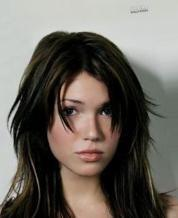

In [48]:
celeba[13][0]

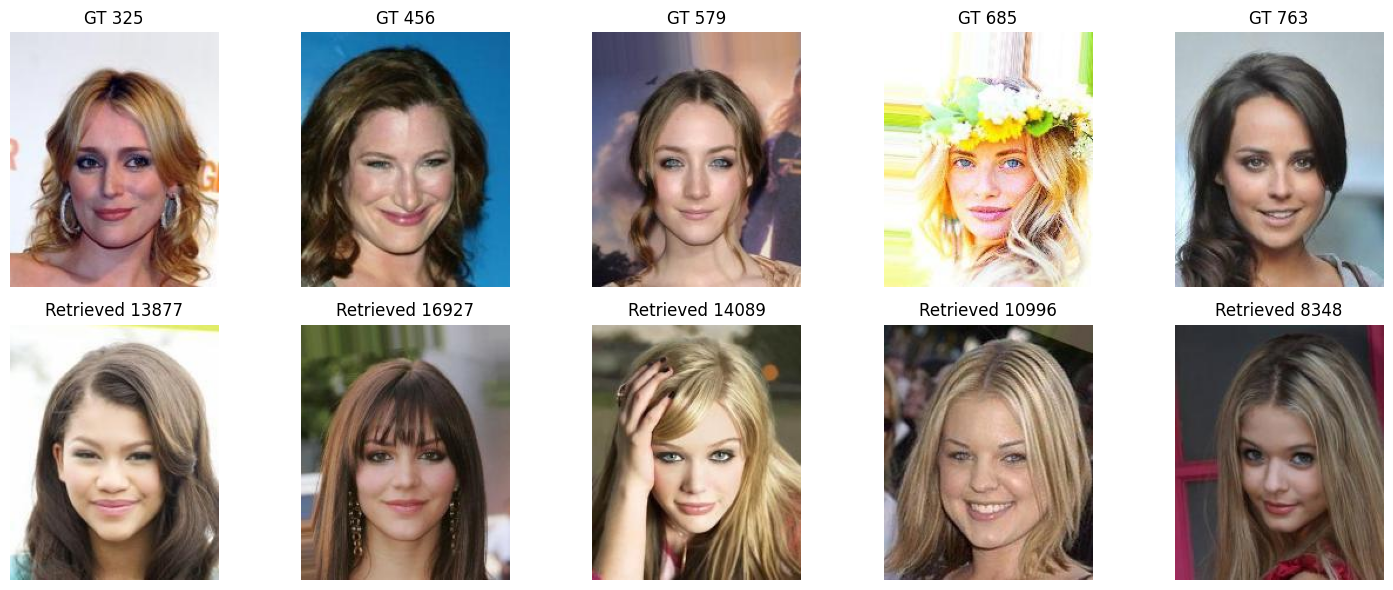

In [49]:
retrieved = [13877, 16927, 14089, 10996, 8348]
ground_truth = [325, 456, 579, 685, 763]

fig, axes = plt.subplots(2, len(retrieved), figsize=(15, 6))
for col, (gt, rt) in enumerate(zip(ground_truth, retrieved)):
    axes[0, col].imshow(celeba[gt][0])
    axes[0, col].set_title(f"GT {gt}")
    axes[0, col].axis("off")

    axes[1, col].imshow(celeba[rt][0])
    axes[1, col].set_title(f"Retrieved {rt}")
    axes[1, col].axis("off")

axes[0, 0].set_ylabel("Ground truth")
axes[1, 0].set_ylabel("Retrieved")
plt.tight_layout()
plt.show()

at least all retrieved imgs are women and seem to be smiling.

The fact that none of them happen to be in the ground-truth set is expected: ground truth requires Hamming ≤ 2 on all 40 attributes, which is a much tighter constraint than just "smiling woman".

we will get more insights on perfonce by running the eval on the entire annotation set and aggregating results. lets work on the aggregation logic:

- lets start simple, we'll compute the avg of each k metric(recall, precision) for each query, across all reference imgs.
- we can track totals like so
```json
{
  "+Smiling": {"ref_counts": 50 ,"Recall@1": 0.05, "Precision@1": 0.05, "Recall@5": 0.12, ...},
  "+Eyeglasses": {"ref_counts": 1000, "Recall@1": 0.08, ...},
}
```
- then compute avg at the end using img ref counts

In [77]:
def initialize_scores():
    scores = {}
    for annotation in annotations:
        attributes = annotation["query"]
        refs = annotation["ground_truth"].keys()
        scores[attributes] = {"ref_counts": len(refs)}

        for k in [1, 5, 10]:
            recall = f"Recall@{k}"
            precision = f"Precision@{k}"
            scores[attributes][recall] = 0
            scores[attributes][precision] = 0

    return scores

In [78]:
scores = initialize_scores()
scores

{'+Smiling': {'ref_counts': 4786,
  'Recall@1': 0,
  'Precision@1': 0,
  'Recall@5': 0,
  'Precision@5': 0,
  'Recall@10': 0,
  'Precision@10': 0},
 '+Eyeglasses': {'ref_counts': 2196,
  'Recall@1': 0,
  'Precision@1': 0,
  'Recall@5': 0,
  'Precision@5': 0,
  'Recall@10': 0,
  'Precision@10': 0},
 '-Heavy_Makeup': {'ref_counts': 4087,
  'Recall@1': 0,
  'Precision@1': 0,
  'Recall@5': 0,
  'Precision@5': 0,
  'Recall@10': 0,
  'Precision@10': 0},
 '+Male': {'ref_counts': 1595,
  'Recall@1': 0,
  'Precision@1': 0,
  'Recall@5': 0,
  'Precision@5': 0,
  'Recall@10': 0,
  'Precision@10': 0},
 '-Young': {'ref_counts': 5355,
  'Recall@1': 0,
  'Precision@1': 0,
  'Recall@5': 0,
  'Precision@5': 0,
  'Recall@10': 0,
  'Precision@10': 0},
 '+Blond_Hair': {'ref_counts': 5469,
  'Recall@1': 0,
  'Precision@1': 0,
  'Recall@5': 0,
  'Precision@5': 0,
  'Recall@10': 0,
  'Precision@10': 0},
 '+Mustache': {'ref_counts': 301,
  'Recall@1': 0,
  'Precision@1': 0,
  'Recall@5': 0,
  'Precision@5': 0

In [79]:
def log(result, query, k):
    # result example: {"Recall@1": 0, "Precision@2": 0}
    recall = f"Recall@{k}"
    precision = f"Precision@{k}"

    scores[query][recall] += result[recall]
    scores[query][precision] += result[precision]

update the eval function with the new `log` function

In [80]:
def run_eval(annotation):
    # split annotation string into invididual attributes
    attributes = annotation["query"].split(",")
    attributes = [attr.strip() for attr in attributes]

    # isolate the +ve and -ve attributes
    positive_attributes = []
    negative_attributes = []
    for attribute in attributes:
        if attribute[0] == "+":
            positive_attributes.append(attribute[1:])
        elif attribute[0] == "-":
            negative_attributes.append(attribute[1:])

    # sum up each set
    positive_attributes = sum_up(positive_attributes)
    negative_attributes = sum_up(negative_attributes)

    # retrieve all the image reference for the query
    refs = [int(value) for value in list(annotation["ground_truth"].keys())]

    for idx in refs:
        # get embedding representation
        img_embed = img_db[idx]

        # apply naive addition and subtruction of the  attributes to the img embed
        # q = v_ref + Σ [+]attr - Σ [-]attr
        query = img_embed + positive_attributes - negative_attributes

        top_10 = compute_similarity(query, img_db, idx)

        # score perfomance
        ground_truths = annotation["ground_truth"][str(idx)]

        for k in [1, 5, 10]:
            # result struct: {"Recall@k": 0, "Precision@k": 0}
            result = evaluate_retrieval(top_10, ground_truths, k, log=False)
            log(result, annotation["query"], k)

In [81]:
# lets test it for just 1 query, all refs
for annotation in annotations[:1]:
    run_eval(annotation)

In [82]:
scores

{'+Smiling': {'ref_counts': 4786,
  'Recall@1': 313,
  'Precision@1': 313.0,
  'Recall@5': 907,
  'Precision@5': 240.39999999999793,
  'Recall@10': 1246,
  'Precision@10': 193.59999999999675},
 '+Eyeglasses': {'ref_counts': 2196,
  'Recall@1': 0,
  'Precision@1': 0,
  'Recall@5': 0,
  'Precision@5': 0,
  'Recall@10': 0,
  'Precision@10': 0},
 '-Heavy_Makeup': {'ref_counts': 4087,
  'Recall@1': 0,
  'Precision@1': 0,
  'Recall@5': 0,
  'Precision@5': 0,
  'Recall@10': 0,
  'Precision@10': 0},
 '+Male': {'ref_counts': 1595,
  'Recall@1': 0,
  'Precision@1': 0,
  'Recall@5': 0,
  'Precision@5': 0,
  'Recall@10': 0,
  'Precision@10': 0},
 '-Young': {'ref_counts': 5355,
  'Recall@1': 0,
  'Precision@1': 0,
  'Recall@5': 0,
  'Precision@5': 0,
  'Recall@10': 0,
  'Precision@10': 0},
 '+Blond_Hair': {'ref_counts': 5469,
  'Recall@1': 0,
  'Precision@1': 0,
  'Recall@5': 0,
  'Precision@5': 0,
  'Recall@10': 0,
  'Precision@10': 0},
 '+Mustache': {'ref_counts': 301,
  'Recall@1': 0,
  'Precisi

In [83]:
def compute_averages(scores):
    avg_scores = {}
    for query in scores.keys():
        avg_scores[query] = {}
        counts = scores[query]["ref_counts"]
        for k in [1, 5, 10]:
            avg_scores[query][f"Recall@{k}"] = round((scores[query][f"Recall@{k}"] / counts), 4)
            avg_scores[query][f"Precision@{k}"] = round((scores[query][f"Precision@{k}"] / counts), 4)

    return avg_scores

In [84]:
averages = compute_averages(scores)
averages

{'+Smiling': {'Recall@1': 0.0654,
  'Precision@1': 0.0654,
  'Recall@5': 0.1895,
  'Precision@5': 0.0502,
  'Recall@10': 0.2603,
  'Precision@10': 0.0405},
 '+Eyeglasses': {'Recall@1': 0.0,
  'Precision@1': 0.0,
  'Recall@5': 0.0,
  'Precision@5': 0.0,
  'Recall@10': 0.0,
  'Precision@10': 0.0},
 '-Heavy_Makeup': {'Recall@1': 0.0,
  'Precision@1': 0.0,
  'Recall@5': 0.0,
  'Precision@5': 0.0,
  'Recall@10': 0.0,
  'Precision@10': 0.0},
 '+Male': {'Recall@1': 0.0,
  'Precision@1': 0.0,
  'Recall@5': 0.0,
  'Precision@5': 0.0,
  'Recall@10': 0.0,
  'Precision@10': 0.0},
 '-Young': {'Recall@1': 0.0,
  'Precision@1': 0.0,
  'Recall@5': 0.0,
  'Precision@5': 0.0,
  'Recall@10': 0.0,
  'Precision@10': 0.0},
 '+Blond_Hair': {'Recall@1': 0.0,
  'Precision@1': 0.0,
  'Recall@5': 0.0,
  'Precision@5': 0.0,
  'Recall@10': 0.0,
  'Precision@10': 0.0},
 '+Mustache': {'Recall@1': 0.0,
  'Precision@1': 0.0,
  'Recall@5': 0.0,
  'Precision@5': 0.0,
  'Recall@10': 0.0,
  'Precision@10': 0.0},
 '+Eyegla

- for each of the 4786 ref images we used to retrieve similar embeddings from the db, only ~6.5% were the first in the list.
- Random chance would be much lower (≈ |ground truth| / 19962), so the baseline is doing better than guessing. This is strenghtened by the fact that CLIP's image embeddings already capture some attribute structure, and naïve vector arithmetic nudges the query in roughly the right direction. But it's far from accurate retrieval.
- lets test this flow using the full eval set

### Tests

In [86]:
# reset scores
scores = initialize_scores()

In [87]:
# lets run the full pipeline
for annotation in annotations:
    run_eval(annotation)

In [88]:
scores

{'+Smiling': {'ref_counts': 4786,
  'Recall@1': 313,
  'Precision@1': 313.0,
  'Recall@5': 907,
  'Precision@5': 240.39999999999793,
  'Recall@10': 1246,
  'Precision@10': 193.59999999999675},
 '+Eyeglasses': {'ref_counts': 2196,
  'Recall@1': 79,
  'Precision@1': 79.0,
  'Recall@5': 256,
  'Precision@5': 61.6000000000002,
  'Recall@10': 403,
  'Precision@10': 53.600000000000335},
 '-Heavy_Makeup': {'ref_counts': 4087,
  'Recall@1': 113,
  'Precision@1': 113.0,
  'Recall@5': 385,
  'Precision@5': 88.00000000000054,
  'Recall@10': 579,
  'Precision@10': 72.80000000000022},
 '+Male': {'ref_counts': 1595,
  'Recall@1': 11,
  'Precision@1': 11.0,
  'Recall@5': 27,
  'Precision@5': 6.800000000000003,
  'Recall@10': 42,
  'Precision@10': 6.099999999999999},
 '-Young': {'ref_counts': 5355,
  'Recall@1': 102,
  'Precision@1': 102.0,
  'Recall@5': 342,
  'Precision@5': 80.80000000000047,
  'Recall@10': 584,
  'Precision@10': 79.79999999999993},
 '+Blond_Hair': {'ref_counts': 5469,
  'Recall@1':

In [89]:
averages = compute_averages(scores)
averages

{'+Smiling': {'Recall@1': 0.0654,
  'Precision@1': 0.0654,
  'Recall@5': 0.1895,
  'Precision@5': 0.0502,
  'Recall@10': 0.2603,
  'Precision@10': 0.0405},
 '+Eyeglasses': {'Recall@1': 0.036,
  'Precision@1': 0.036,
  'Recall@5': 0.1166,
  'Precision@5': 0.0281,
  'Recall@10': 0.1835,
  'Precision@10': 0.0244},
 '-Heavy_Makeup': {'Recall@1': 0.0276,
  'Precision@1': 0.0276,
  'Recall@5': 0.0942,
  'Precision@5': 0.0215,
  'Recall@10': 0.1417,
  'Precision@10': 0.0178},
 '+Male': {'Recall@1': 0.0069,
  'Precision@1': 0.0069,
  'Recall@5': 0.0169,
  'Precision@5': 0.0043,
  'Recall@10': 0.0263,
  'Precision@10': 0.0038},
 '-Young': {'Recall@1': 0.019,
  'Precision@1': 0.019,
  'Recall@5': 0.0639,
  'Precision@5': 0.0151,
  'Recall@10': 0.1091,
  'Precision@10': 0.0149},
 '+Blond_Hair': {'Recall@1': 0.0272,
  'Precision@1': 0.0272,
  'Recall@5': 0.0874,
  'Precision@5': 0.0229,
  'Recall@10': 0.1381,
  'Precision@10': 0.0206},
 '+Mustache': {'Recall@1': 0.0698,
  'Precision@1': 0.0698,
  

In [94]:
def visualize_results():
    queries = list(averages.keys())
    metrics = ["Recall@1", "Recall@5", "Recall@10", "Precision@1", "Precision@5", "Precision@10"]
    x = np.arange(len(queries))
    w = 0.13

    fig, ax = plt.subplots(figsize=(14, 6))
    for i, m in enumerate(metrics):
        ax.bar(x + i * w, [averages[q][m] for q in queries], w, label=m)

    ax.set_xticks(x + w * 2.5)
    ax.set_xticklabels(queries, rotation=45, ha="right")
    ax.set_ylabel("Score")
    ax.legend()
    plt.tight_layout()
    plt.show()

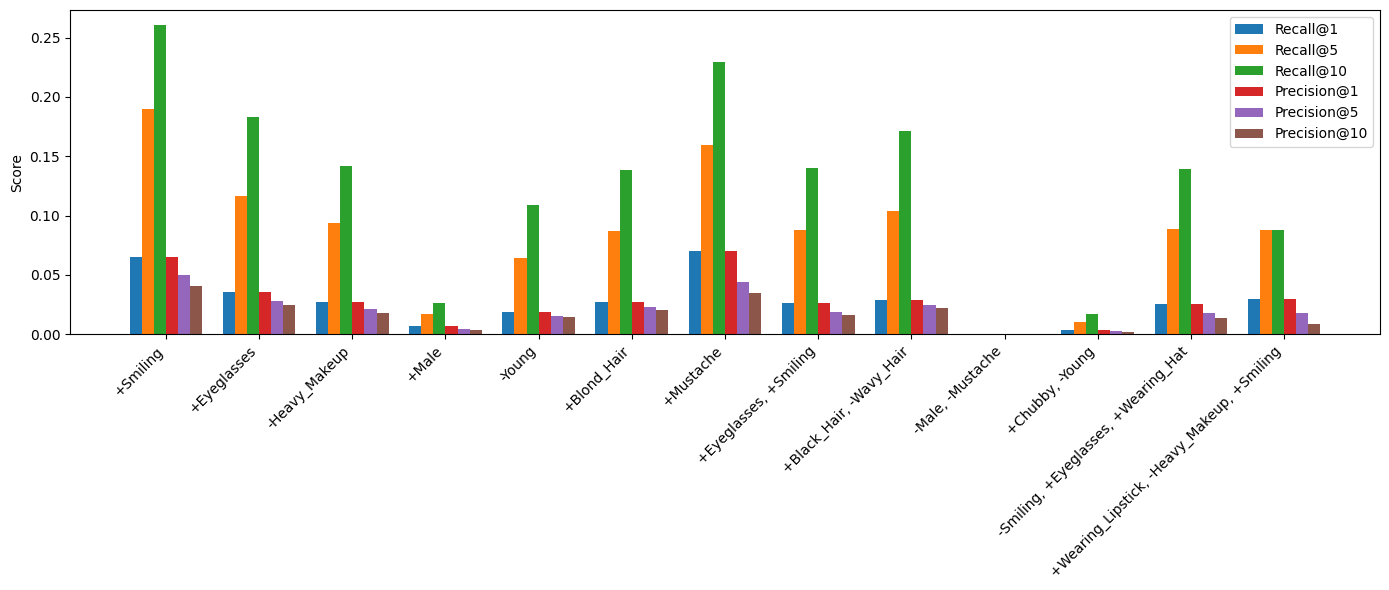

In [95]:
visualize_results()

- `-Male, -Mustache`: 0 hits across the board. small gt pool (27 src imgs)? or double -ve breaking the arithmetic? or both attrs pushing same direction (redundancy)?
- `+Mustache` vs `+Male`: both signal masculine features but mustache does way better. why?
- `+Chubby, -Young`: near zero. rare attribute + negative combo. how often does it actually appear in data?
- precision values tiny across the board (<0.07). large gt lists explain some of it, but possibly also a sign naive composition is fundamentally weak
- single +ve attrs outperform multi-attr queries. stacking conditions breaks naive arithmetic. this is exactly what threads 2 & 4 should fix

### Investigating test results

...coming soon